# Diferenças regionais nas contratações públicas (Lei nº 14.133/2021): comparação entre Unidades da Federação

**Integrantes:** Enzo Ribeiro Silva e Gustavo Lopes Francisco  
**Desafio escolhido:** A — Compras públicas e diferenças regionais

## 1. Título provisório
Diferenças regionais nas contratações públicas da Lei nº 14.133/2021: uma comparação entre cinco UFs com dados do Compras.gov.br

## 2. Problema de pesquisa
A distribuição das contratações públicas apresenta diferenças entre as Unidades da Federação?

**Justificativa:** as contratações públicas movimentam grandes volumes de recursos e são realizadas por órgãos de portes muito diferentes. Entender se o volume e os valores variam entre as UFs ajuda a identificar padrões regionais que merecem investigação mais aprofundada.

## 3. Pergunta de pesquisa
Entre **SP, RJ, MG, BA e RS**, considerando as contratações publicadas no PNCP entre **01/05/2025 e 15/05/2025**, na modalidade "Pregão - Eletrônico" (`codigoModalidade = 5`), a **quantidade de contratações** e o **valor total estimado** diferem entre as UFs?

## 4. Hipótese
- **H0:** a distribuição do valor total estimado das contratações é a mesma nas cinco UFs.
- **H1:** pelo menos uma UF apresenta distribuição diferente das demais.
- **Expectativa inicial:** UFs com mais órgãos compradores (como SP e MG) devem concentrar maior quantidade de contratações. Para os valores, não há expectativa clara, e a análise é exploratória.

## 5. Fonte dos dados
API pública de Dados Abertos do Compras.gov.br: https://dadosabertos.compras.gov.br  
Unidade de análise: **uma contratação** (`idCompra`).

## 6. Endpoint utilizado
`GET /modulo-contratacoes/1_consultarContratacoes_PNCP_14133` (contratações realizadas no contexto da Lei nº 14.133/2021).

## 7. Parâmetros da API

| Parâmetro | Valor |
|---|---|
| `dataPublicacaoPncpInicial` | 2025-05-01 |
| `dataPublicacaoPncpFinal` | 2025-05-15 |
| `codigoModalidade` | 5 |
| `unidadeOrgaoUfSigla` | SP, RJ, MG, BA e RS (uma consulta para cada UF) |
| `tamanhoPagina` | 50 |
| Páginas coletadas por UF | 4 (até 200 registros por UF) |

**Variáveis utilizadas:** `idCompra`, `modalidadeNome`, `valorTotalEstimado`, `dataPublicacaoPncp`, `objetoCompra` e `unidadeOrgaoNomeUnidade` (quando disponíveis), além da coluna `uf_consulta`, criada no código para identificar a UF de cada consulta.

## 8. Período analisado
Publicações no PNCP de **01/05/2025 a 15/05/2025**. A data da coleta é de **24/11/2026**.

## 9. Código de coleta
O fluxo segue a separação indicada na atividade: **coleta → dados brutos → tratamento → dados analisados**.

In [ ]:
#%pip install requests pandas numpy matplotlib scipy -q

In [2]:
import time
from datetime import datetime
from itertools import combinations

import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

In [3]:
BASE_URL = "https://dadosabertos.compras.gov.br"

ENDPOINT_CONTRATACOES = "/modulo-contratacoes/1_consultarContratacoes_PNCP_14133"

url = BASE_URL + ENDPOINT_CONTRATACOES

print(url)

https://dadosabertos.compras.gov.br/modulo-contratacoes/1_consultarContratacoes_PNCP_14133


In [4]:
def extrair_registros(json_resposta):
    if isinstance(json_resposta, list):
        return json_resposta

    if not isinstance(json_resposta, dict):
        return []

    for chave in ["resultado", "resultados", "data", "content"]:
        if chave in json_resposta and isinstance(json_resposta[chave], list):
            return json_resposta[chave]

    return []


def consultar_api(endpoint, params=None):
    resposta = requests.get(
        BASE_URL + endpoint,
        params=params,
        timeout=60
    )

    print("Status HTTP:", resposta.status_code)
    print("URL:", resposta.url)

    resposta.raise_for_status()

    dados = resposta.json()
    registros = extrair_registros(dados)

    print("Registros encontrados:", len(registros))

    return dados, pd.json_normalize(registros)


def coletar_paginas(endpoint, parametros, numero_paginas=3):
    todos = []

    for pagina in range(1, numero_paginas + 1):

        params_pagina = parametros.copy()
        params_pagina["pagina"] = pagina

        resposta = requests.get(
            BASE_URL + endpoint,
            params=params_pagina,
            timeout=60
        )

        resposta.raise_for_status()

        registros = extrair_registros(resposta.json())

        print(f"Página {pagina}: {len(registros)} registros")

        if len(registros) == 0:
            break

        todos.extend(registros)

    return pd.json_normalize(todos)

In [5]:
# Parâmetros do estudo (registrados para garantir a reprodutibilidade)
UFS = ["SP", "RJ", "MG", "BA", "RS"]
CODIGO_MODALIDADE = 5
DATA_INICIAL = "2025-05-01"
DATA_FINAL = "2025-05-15"
TAMANHO_PAGINA = 50
NUMERO_PAGINAS = 4

params_base = {
    "tamanhoPagina": TAMANHO_PAGINA,
    "dataPublicacaoPncpInicial": DATA_INICIAL,
    "dataPublicacaoPncpFinal": DATA_FINAL,
    "codigoModalidade": CODIGO_MODALIDADE
}

# Data da coleta
data_coleta = datetime.now().strftime("%Y-%m-%d %H:%M")
print("Data da coleta:", data_coleta)

params_base

Data da coleta: 2026-11-24 01:55


{'tamanhoPagina': 50,
 'dataPublicacaoPncpInicial': '2025-05-01',
 'dataPublicacaoPncpFinal': '2025-05-15',
 'codigoModalidade': 5}

### Consulta piloto
Antes da coleta principal, uma consulta pequena (10 registros, UF = SP) verifica se o endpoint está disponível, se os campos necessários existem e se há muitos valores ausentes.

In [6]:
params_piloto = params_base.copy()
params_piloto["pagina"] = 1
params_piloto["tamanhoPagina"] = 10
params_piloto["unidadeOrgaoUfSigla"] = "SP"

dados_piloto, df_piloto = consultar_api(ENDPOINT_CONTRATACOES, params_piloto)

print("\nChaves do JSON:", list(dados_piloto.keys()) if isinstance(dados_piloto, dict) else "lista")
print("Dimensão:", df_piloto.shape)

Status HTTP: 200
URL: https://dadosabertos.compras.gov.br/modulo-contratacoes/1_consultarContratacoes_PNCP_14133?tamanhoPagina=10&dataPublicacaoPncpInicial=2025-05-01&dataPublicacaoPncpFinal=2025-05-15&codigoModalidade=5&pagina=1&unidadeOrgaoUfSigla=SP
Registros encontrados: 10

Chaves do JSON: ['resultado', 'totalRegistros', 'totalPaginas', 'paginasRestantes']
Dimensão: (10, 52)


In [7]:
# Os campos necessários estão presentes?
colunas_necessarias = ["idCompra", "modalidadeNome", "valorTotalEstimado", "dataPublicacaoPncp", "objetoCompra"]

for coluna in colunas_necessarias:
    print(f"{coluna}: {'OK' if coluna in df_piloto.columns else 'AUSENTE'}")

if "modalidadeNome" in df_piloto.columns:
    print("\nModalidade(s) retornada(s):", df_piloto["modalidadeNome"].unique())

# Há muitos valores ausentes?
df_piloto.isna().mean().mul(100).round(1).sort_values(ascending=False).head(10)

idCompra: OK
modalidadeNome: OK
valorTotalEstimado: OK
dataPublicacaoPncp: OK
objetoCompra: OK

Modalidade(s) retornada(s): <ArrowStringArray>
['Pregão - Eletrônico']
Length: 1, dtype: str


orgaoSubrogadoPoderId            100.0
orgaoSubrogadoEsferaId           100.0
orgaoSubrogadoRazaoSocial        100.0
orgaoSubrogadoCnpj               100.0
unidadeSubrogadaNomeUnidade      100.0
unidadeSubrogadaUfSigla          100.0
unidadeSubrogadaCodigoUnidade    100.0
unidadeSubrogadaMunicipioNome    100.0
unidadeSubrogadaCodigoIbge       100.0
anoCompraPncp                      0.0
dtype: float64

**Resultado da consulta piloto:**
- Endpoint disponível: sim (status HTTP 200 e 10 registros retornados)
- Campos necessários presentes: sim (`idCompra`, `modalidadeNome`, `valorTotalEstimado`, `dataPublicacaoPncp` e `objetoCompra`)
- Modalidade de código 5: Pregão - Eletrônico (retornada em `modalidadeNome`)
- Quantidade de registros suficiente: sim (a página veio completa, com 10 de 10 registros, e a API informa o total em `totalRegistros`; total de SP no período: 1429)
- Valores ausentes relevantes: nenhum nos campos do estudo. Apenas 9 colunas de órgão/unidade subrogada (`orgaoSubrogado*` e `unidadeSubrogada*`) estavam 100% ausentes, e elas não são usadas na análise
- Consulta reproduzível (parâmetros fixos e período histórico): sim

In [ ]:
# Quantidade total de contratações por UF, informada pela própria API (sem baixar todos os registros)
def total_registros_uf(uf):
    p = params_base.copy()
    p["pagina"] = 1
    p["tamanhoPagina"] = 10
    p["unidadeOrgaoUfSigla"] = uf

    r = requests.get(url, params=p, timeout=60)
    r.raise_for_status()

    j = r.json()
    return j.get("totalRegistros") if isinstance(j, dict) else None


totais = {}

for uf in UFS:
    totais[uf] = total_registros_uf(uf)
    time.sleep(0.5)

df_totais = pd.DataFrame({"uf": list(totais.keys()), "total_contratacoes": list(totais.values())})

df_totais

,uf,total_contratacoes
0,SP,1429
1,RJ,346
2,MG,205
3,BA,112
4,RS,132


In [23]:
df_totais["percentual"] = (df_totais["total_contratacoes"] / df_totais["total_contratacoes"].sum() * 100).round(1)
df_totais

,uf,total_contratacoes,percentual
0,SP,1429,64.3
1,RJ,346,15.6
2,MG,205,9.2
3,BA,112,5.0
4,RS,132,5.9


In [9]:
# Coleta principal: 4 páginas de 50 registros para cada UF
lista_dfs = []

for uf in UFS:
    p = params_base.copy()
    p["unidadeOrgaoUfSigla"] = uf

    print(f"\nColetando {uf}...")

    df_uf = coletar_paginas(ENDPOINT_CONTRATACOES, p, numero_paginas=NUMERO_PAGINAS)
    df_uf["uf_consulta"] = uf

    lista_dfs.append(df_uf)
    time.sleep(0.5)

df_bruto = pd.concat(lista_dfs, ignore_index=True)

print("\nDimensão do dado bruto:", df_bruto.shape)


Coletando SP...
Página 1: 50 registros
Página 2: 50 registros
Página 3: 50 registros
Página 4: 50 registros

Coletando RJ...
Página 1: 50 registros
Página 2: 50 registros
Página 3: 50 registros
Página 4: 50 registros

Coletando MG...
Página 1: 50 registros
Página 2: 50 registros
Página 3: 50 registros
Página 4: 50 registros

Coletando BA...
Página 1: 50 registros
Página 2: 50 registros
Página 3: 12 registros
Página 4: 0 registros

Coletando RS...
Página 1: 50 registros
Página 2: 50 registros
Página 3: 32 registros
Página 4: 0 registros

Dimensão do dado bruto: (844, 53)


In [10]:
# Preserva uma cópia dos dados brutos para não consultar a API novamente
nome_arquivo_bruto = f"contratacoes_bruto_{datetime.now().strftime('%Y%m%d')}.csv"

df_bruto.to_csv(nome_arquivo_bruto, index=False, encoding="utf-8-sig")

print("Arquivo salvo:", nome_arquivo_bruto)

Arquivo salvo: contratacoes_bruto_20261124.csv


## 10. Construção do DataFrame
O `DataFrame` bruto foi construído com `pd.json_normalize()` dentro da função `coletar_paginas`. A partir daqui trabalhamos em uma cópia, preservando o dado bruto.

In [11]:
df = df_bruto.copy()

print("Dimensão:", df.shape)

df.head()

Dimensão: (844, 53)


,idCompra,numeroControlePNCP,anoCompraPncp,sequencialCompraPncp,orgaoEntidadeCnpj,orgaoSubrogadoCnpj,codigoOrgao,orgaoEntidadeRazaoSocial,orgaoSubrogadoRazaoSocial,orgaoEntidadeEsferaId,...,modoDisputaNomePncp,valorTotalEstimado,valorTotalHomologado,dataInclusaoPncp,dataAtualizacaoPncp,dataPublicacaoPncp,dataAberturaPropostaPncp,dataEncerramentoPropostaPncp,contratacaoExcluida,uf_consulta
0,92967905900012025,48198725000162-1-000052/2025,2025,52,48198725000162,None,83589,CAMARA MUNICIPAL DE MOGI GUACU,None,M,...,Aberto,293237.06,288069.0,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T07:16:01,2025-05-02T08:00:00,2025-05-16T08:30:00,False,SP
1,09013305900682025,46374500000194-1-003439/2025,2025,3439,46374500000194,None,34952,SECRETARIA DE ESTADO DA SAUDE,None,E,...,Aberto,91698.92,7525.4,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T07:16:21,2025-05-02T08:00:00,2025-05-16T09:35:00,False,SP
2,18015805900142025,46377800000127-1-001783/2025,2025,1783,46377800000127,None,35311,SAO PAULO SECRETARIA DA SEGURANCA PUBLICA,None,E,...,Aberto,52245.06,44000.0,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T07:16:35,2025-05-02T08:00:00,2025-05-21T09:00:00,False,SP
3,53210105907532025,60747318000162-1-000718/2025,2025,718,60747318000162,None,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,None,E,...,Aberto-Fechado,385875.75,174300.0,2025-05-02T07:16:43,2025-05-02T07:16:43,2025-05-02T07:16:43,2025-05-05T08:00:00,2025-05-28T09:00:00,False,SP
4,53210105907542025,60747318000162-1-000719/2025,2025,719,60747318000162,None,84184,INSTITUTO DE ASSISTENCIA MEDICA AO SERVIDOR PU...,None,E,...,Aberto-Fechado,577107.45,275745.0,2025-05-02T07:17:01,2025-05-02T07:17:01,2025-05-02T07:17:01,2025-05-05T08:00:00,2025-05-29T09:00:00,False,SP


## 11. Avaliação da qualidade dos dados

In [12]:
# Registros coletados por UF
print(df["uf_consulta"].value_counts())

# Duplicidades
print("\nLinhas duplicadas completas:", df.duplicated().sum())

if "idCompra" in df.columns:
    print("IDs de compra duplicados:", df["idCompra"].duplicated().sum())

uf_consulta
SP    200
RJ    200
MG    200
RS    132
BA    112
Name: count, dtype: int64

Linhas duplicadas completas: 0
IDs de compra duplicados: 0


In [13]:
# Valores ausentes
percentual_ausentes = (
    df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
)

percentual_ausentes.head(15)

unidadeSubrogadaUfSigla          100.000000
orgaoSubrogadoEsferaId           100.000000
orgaoSubrogadoPoderId            100.000000
orgaoSubrogadoRazaoSocial        100.000000
orgaoSubrogadoCnpj               100.000000
unidadeSubrogadaNomeUnidade      100.000000
unidadeSubrogadaMunicipioNome    100.000000
unidadeSubrogadaCodigoUnidade    100.000000
unidadeSubrogadaCodigoIbge       100.000000
valorTotalHomologado              12.440758
sequencialCompraPncp               0.000000
idCompra                           0.000000
orgaoEntidadeCnpj                  0.000000
orgaoEntidadePoderId               0.000000
orgaoEntidadeEsferaId              0.000000
dtype: float64

## 12. Limpeza
Critérios adotados:
1. remover contratações duplicadas (mesmo `idCompra`);
2. converter `valorTotalEstimado` para número e `dataPublicacaoPncp` para `datetime`;
3. remover registros sem valor estimado ou com valor menor ou igual a zero;
4. **não remover valores extremos**: eles são investigados e tratados com métodos robustos (escala logarítmica e testes não paramétricos).

In [14]:
n_inicial = len(df)

# 1. Duplicidades
if "idCompra" in df.columns:
    df = df.drop_duplicates(subset="idCompra")
else:
    df = df.drop_duplicates()

n_apos_duplicidade = len(df)

# 2. Conversão de tipos
df["valorTotalEstimado"] = pd.to_numeric(df["valorTotalEstimado"], errors="coerce")
df["dataPublicacaoPncp"] = pd.to_datetime(df["dataPublicacaoPncp"], errors="coerce")

# 3. Valores válidos
df = df[df["valorTotalEstimado"].notna() & (df["valorTotalEstimado"] > 0)].copy()

print("Registros iniciais:", n_inicial)
print("Removidos por duplicidade:", n_inicial - n_apos_duplicidade)
print("Removidos por valor ausente ou não positivo:", n_apos_duplicidade - len(df))
print("Registros analisados:", len(df))

Registros iniciais: 844
Removidos por duplicidade: 0
Removidos por valor ausente ou não positivo: 32
Registros analisados: 812


In [15]:
# Investigação de valores extremos (regra do intervalo interquartil)
q1, q3 = df["valorTotalEstimado"].quantile([0.25, 0.75])
limite_superior = q3 + 1.5 * (q3 - q1)

print(f"Limite superior (Q3 + 1,5 x IQR): R$ {limite_superior:,.2f}")
print("Registros acima do limite:", (df["valorTotalEstimado"] > limite_superior).sum())

colunas_exibir = [c for c in ["uf_consulta", "unidadeOrgaoNomeUnidade", "objetoCompra", "valorTotalEstimado"] if c in df.columns]

df.nlargest(5, "valorTotalEstimado")[colunas_exibir]

Limite superior (Q3 + 1,5 x IQR): R$ 2,500,488.46
Registros acima do limite: 110


,uf_consulta,unidadeOrgaoNomeUnidade,objetoCompra,valorTotalEstimado
468,MG,CONSORCIO INTER.DE DESENV.RURAL SUSTENTAVEL,"Registro de preços para futura, eventual e par...",2.411685e+08
357,RJ,GRUPAMENTO DE APOIO DOS AFONSOS,Contratação de empresa de engenharia especiali...,9.658599e+07
599,MG,HOSPITAL DAS CLÍNICAS DE MINAS GERAIS,"Prestação de serviços contínuos de limpeza, de...",7.557212e+07
800,RS,PREFEITURA MUNICIPAL DE SANTA MARIA/RS,Contratação de serviços de circuito fechado de...,6.612263e+07
37,SP,ESP-INST. ASSIST. MEDICA SERV. PUB. ESTADUAL,Contratação De Empresa de Saúde para prestação...,5.872523e+07


In [22]:
# Investigação de valores muito baixos
df.nsmallest(10, "valorTotalEstimado")[colunas_exibir]

,uf_consulta,unidadeOrgaoNomeUnidade,objetoCompra,valorTotalEstimado
695,BA,EBA - PROCURADORIA GERAL DE JUSTICA DA BAHIA,Registro de preços para prestação de serviço d...,1.00
669,BA,EBA - PROCURADORIA GERAL DE JUSTICA DA BAHIA,Prestação de serviços de engenharia para manut...,3.00
220,RJ,PREFEITURA MUNICIPAL DO RIO DE JANEIRO - RJ,"Contratação de serviços de DIAGNÓSTICO, MONITO...",50.00
26,SP,ESP-DELEG.SECC.POLICIA DE SB DO CAMPO,Prestação de serviços de nutrição e alimentaçã...,51.48
818,RS,INST.FED.SUL R.GRANDENSE/SAPUCAIA DO SUL,O objeto da presente licitação é a discriminaç...,190.63
630,BA,INST.FED.DA BAHIA/CAMPUS CAMAÇARI,Concessão Administrativa de Uso de Espaço Físi...,192.30
810,RS,UNIVERSIDADE FEDERAL DE STA.MARIA/RS,Concessão onerosa de área física de 123 m² de ...,388.72
491,MG,SECRETARIA MUNICIPAL DE EDU. CULTURA - MG,Contratação de empresa para fornecimento e ins...,1547.77
79,SP,ESP-HOSP.EST. DR.OSWALDO B. FARIA -MIRANDOPOL,Contratação de Serviço de manutenção preventiv...,1825.00
830,RS,CONSELHO REG.DE ENG.ARQ.AGRON.DO R.G DO SUL,Prestação de serviços na área de integração de...,1827.00


## 13. Estatística descritiva

In [16]:
resumo = df.groupby("uf_consulta")["valorTotalEstimado"].agg(["count", "mean", "median", "std", "min", "max"])

# Coeficiente de variação
resumo["cv"] = resumo["std"] / resumo["mean"]

resumo.loc[[uf for uf in UFS if uf in resumo.index]].round(2)

,count,mean,median,std,min,max,cv
uf_consulta,,,,,,,
SP,185,1393210.00,153885.59,5237407.30,51.48,5.872523e+07,3.76
RJ,191,3426410.70,477401.20,9579522.56,50.00,9.658599e+07,2.80
MG,194,2985651.78,300049.90,18317744.49,1547.77,2.411685e+08,6.14
BA,112,1383600.24,425885.67,4961906.25,1.00,5.153857e+07,3.59
RS,130,1594866.16,230403.55,6394097.74,190.63,6.612263e+07,4.01


## 14. Visualizações

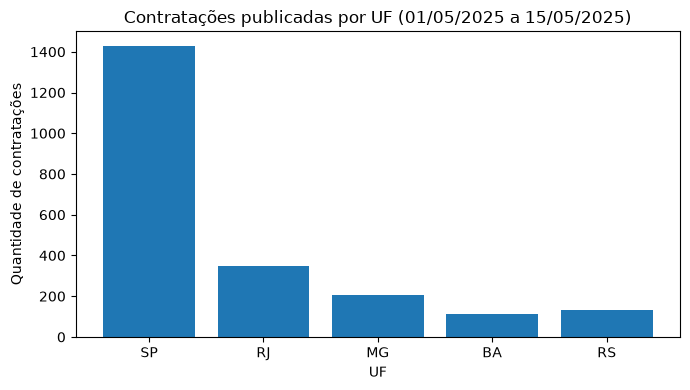

In [ ]:
# Quantidade total de contratações por UF (informada pela API)
df_graf = df_totais.dropna(subset=["total_contratacoes"])

if len(df_graf) > 0:
    plt.figure(figsize=(7, 4))
    plt.bar(df_graf["uf"], df_graf["total_contratacoes"])
    plt.title("Contratações publicadas por UF (01/05/2025 a 15/05/2025)")
    plt.xlabel("UF")
    plt.ylabel("Quantidade de contratações")
    plt.tight_layout()
    plt.show()
else:
    print("A API não retornou o total de registros. Veja as chaves do JSON piloto.")

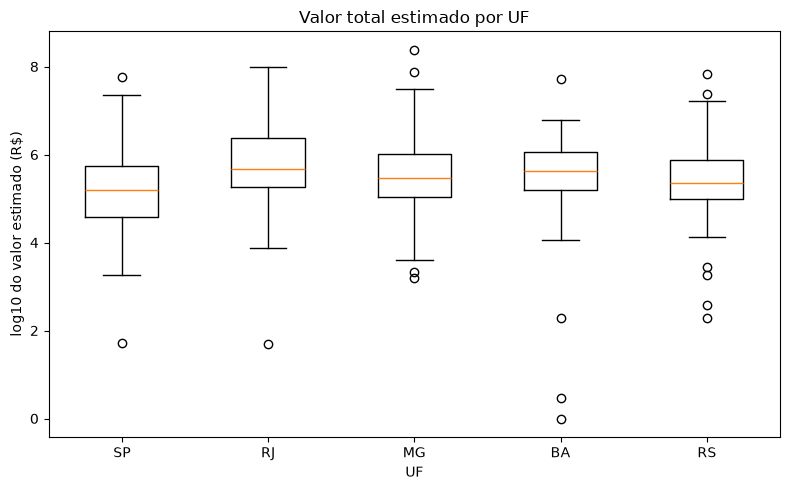

In [18]:
# Distribuição dos valores estimados por UF (escala logarítmica, pois os valores são muito assimétricos)
df["log_valor"] = np.log10(df["valorTotalEstimado"])

ufs_validas = [uf for uf in UFS if (df["uf_consulta"] == uf).sum() > 0]
grupos_log = [df.loc[df["uf_consulta"] == uf, "log_valor"] for uf in ufs_validas]

plt.figure(figsize=(8, 5))
plt.boxplot(grupos_log)
plt.xticks(range(1, len(ufs_validas) + 1), ufs_validas)
plt.title("Valor total estimado por UF")
plt.xlabel("UF")
plt.ylabel("log10 do valor estimado (R$)")
plt.tight_layout()
plt.show()

## 15. Comparação quantitativa
Como os valores são muito assimétricos, usamos o **teste de Kruskal-Wallis**, que não exige distribuição normal. Se houver diferença, comparamos as UFs duas a duas com o teste de Mann-Whitney, com correção de Bonferroni.

In [19]:
grupos_valores = [df.loc[df["uf_consulta"] == uf, "valorTotalEstimado"] for uf in ufs_validas]

h, p = stats.kruskal(*grupos_valores)

n_total = sum(len(g) for g in grupos_valores)
epsilon2 = h / (n_total - 1)  # tamanho de efeito

print(f"Kruskal-Wallis: H = {h:.3f} | p = {p:.4g} | epsilon² = {epsilon2:.4f}")

Kruskal-Wallis: H = 45.767 | p = 2.753e-09 | epsilon² = 0.0564


In [20]:
pares = list(combinations(ufs_validas, 2))
linhas = []

for a, b in pares:
    ga = df.loc[df["uf_consulta"] == a, "valorTotalEstimado"]
    gb = df.loc[df["uf_consulta"] == b, "valorTotalEstimado"]

    u, p_par = stats.mannwhitneyu(ga, gb, alternative="two-sided")

    linhas.append({
        "comparação": f"{a} x {b}",
        "U": u,
        "p": p_par,
        "p_ajustado": min(p_par * len(pares), 1)
    })

pd.DataFrame(linhas).round(4)

,comparação,U,p,p_ajustado
0,SP x RJ,11172.0,0.0000,0.0000
1,SP x MG,14296.0,0.0006,0.0062
2,SP x BA,7231.0,0.0000,0.0001
3,SP x RS,10248.0,0.0256,0.2559
4,RJ x MG,21954.0,0.0017,0.0170
5,RJ x BA,11906.0,0.1004,1.0000
6,RJ x RS,15525.0,0.0001,0.0014
7,MG x BA,9918.0,0.2047,1.0000
8,MG x RS,13444.0,0.3132,1.0000
9,BA x RS,8452.0,0.0310,0.3097


In [21]:
# Salva os dados analisados
df.to_csv("contratacoes_analisadas.csv", index=False, encoding="utf-8-sig")

## 16. Discussão

- **Quantidade:** a UF com mais contratações no período foi SP (1.429, 64,3% do total das cinco UFs) e a com menos foi BA (112, 5,0%). A ordem foi SP > RJ (346) > MG (205) > RS (132) > BA (112). A expectativa inicial se confirmou para SP, mas MG ficou atrás do RJ.
- **Valores:** as medianas do valor estimado variaram de R$ 153.885,59 (SP) a R$ 477.401,20 (RJ). O coeficiente de variação foi mais alto em MG (6,14), influenciado por uma contratação de R$ 241,2 milhões (registro de preços de um consórcio de desenvolvimento rural), e mais baixo no RJ (2,80).
- **Teste estatístico:** Kruskal-Wallis com H = 45,767 e p = 2,75 × 10⁻⁹. Como p < 0,05, há evidência de diferença entre as UFs. Nas comparações pareadas com correção de Bonferroni, as diferenças ocorreram em SP x RJ, SP x MG, SP x BA, RJ x MG e RJ x RS (p ajustado < 0,05). As demais combinações não foram significativas.
- **Tamanho do efeito:** epsilon² = 0,0564, efeito pequeno a moderado. A diferença existe, mas a UF explica pouco da variação, que é grande dentro de cada UF.
- **Interpretação:** diferenças encontradas não significam que a localização as **causou**. Podem refletir o objeto comprado, a quantidade adquirida, o porte dos órgãos, a logística e o período. Chama atenção que SP, com mais contratações, teve a menor mediana, o que sugere maior presença de compras de menor valor. Essa hipótese não foi testada neste estudo.

## 17. Limitações
- Os valores foram analisados em uma **amostra** dos primeiros registros devolvidos pela API (até 200 por UF), com cobertura variável: SP 200 de 1.429 (14,0%), RJ 200 de 346 (57,8%) e MG 200 de 205 (97,6%). BA (112) e RS (132) foram coletadas por inteiro. Os resultados de SP, em especial, podem não representar todas as contratações da UF.
- Apenas **uma modalidade** e um período de **15 dias** foram analisados, então os resultados não se estendem a outras modalidades ou épocas.
- `valorTotalEstimado` é um valor **estimado** no momento da contratação, não o valor efetivamente pago.
- Dos 844 registros coletados, 32 (3,8%) foram removidos por valor estimado ausente ou não positivo, restando 812. Outros 110 ficaram acima do limite do intervalo interquartil (R$ 2.500.488,46) e foram mantidos. Há também valores muito baixos (a partir de R$ 1,00 em BA, R$ 50,00 no RJ e R$ 51,48 em SP) que podem ser valores simbólicos e não foram removidos.
- A API pode sofrer alterações de disponibilidade, estrutura e quantidade de registros. A data da coleta está registrada no código (`data_coleta`).
- A quantidade de contratações por UF depende do campo de total informado pela API.
- Dados administrativos não são um experimento: associação não implica causalidade.
- As contratações de um mesmo órgão não são independentes entre si (o mesmo órgão aparece várias vezes na amostra), o que o teste de Kruskal-Wallis não considera.

## 18. Conclusão

Respondendo à pergunta de pesquisa: entre SP, RJ, MG, BA e RS, no período de 01/05/2025 a 15/05/2025 e na modalidade Pregão - Eletrônico (código 5), há evidência de diferença no valor total estimado das contratações (Kruskal-Wallis, p = 2,75 × 10⁻⁹), embora o efeito seja pequeno a moderado (epsilon² = 0,056). As diferenças se concentraram nos pares que envolvem SP e RJ, com o RJ apresentando a maior mediana e SP a menor. Quanto à quantidade, SP concentrou o maior número de contratações (1.429, 64,3% do total das cinco UFs). A hipótese H0 foi rejeitada. Por se tratar de amostra e de análise observacional, os resultados são exploratórios e indicam caminhos para estudos futuros, como ampliar o período, incluir outras modalidades e controlar o tipo de objeto comprado.